## Performance Prediction & Composition via Stochastic Network Calculus (SNC): Real Services

This notebook walks through the probabilistic end-to-end performance modeling methodology (PEGASUS) step by step on
real services, the counterpart of `1_method_synthetic.ipynb`, which does the same on a small synthetic system. The section
numbers are those of `1_method_synthetic.ipynb`, so that the two notebooks can be read side by side; a section that has no
counterpart for real data says so in one paragraph.

1. **Real system (Section 1):** the training data from the second testbed campaign in `statics/results_milos_v2/` (the B1
   experiments of `new_experiments.md`), and the ground truth, the measured latencies of the chain.
2. **Learning (Sections 2–5):** two Gaussian Processes (GPs) per service predict the mean execution time of an
   item and the scatter of single items from the configuration.
3. **Node bounds (Section 6):** a bound on the latency (sojourn time) of one service that is violated with probability
   at most $\varepsilon$: the execution-time bound as a baseline (6a), the SNC queueing bound (6b), the SNC bound with
   propagated arrival models (6c), the martingale bound (6d) and the martingale bound with propagated service spacing
   (6e), checked on held-out configurations (6f).
4. **Composition (Section 7):** the union bound over the node bounds (7a) and the network service curve with Hölder's
   inequality (7b) give an end-to-end bound for any dependence between services. Composition by independence (7c) and
   the replay of monitored node latencies (7f) are baselines; 7g compares all of them at one configuration.

**Measured ground truth.** Every service of the second campaign queues its items FIFO and gives each item to the first
free one of its workers (one to four per service in the evaluated experiment), so the testbed is a chain of FIFO queues
with several workers under Poisson arrivals. The bounds describe a service with several workers by a single-server
queue per worker (cyclic assignment, Section 6b). The ground truth is the latency that the testbed measured. (`2_evaluation.ipynb` evaluates
the first campaign, whose services released their items only once per second; there the ground truth is emulated by
replaying the measured processing times through FIFO queues.) One part of the measured latency is not in the model of
the bounds: the handover of a request from one service to the next.

**Held-out runs, not an unseen composition.** The second campaign has one topology per application, and every service
occurs only in that topology, so a service cannot be trained on pipelines of another topology as in the first
campaign. The runs of the evaluated experiment, `b1-vision-1-workers` (one to four workers and one to four cores per
service), are split at random: `n_train` runs train the models, the others are held out. The models therefore know the
topology of the evaluated chain, but none of its held-out runs. The B1 specification in `new_experiments.md`
(five instances per application, every service in at least two of them) restores the unseen composition.

The violation probability $\varepsilon$ is `alpha` in the code. The reader of the campaign and its measured latencies are in
`pegasus/real_data.py`, the bounds in `pegasus/bounds.py`, the models in `pegasus/service_gp.py`, and the baselines in
`pegasus/baselines.py` and `pegasus/baselines_chain.py`. `2_evaluation.ipynb` evaluates the methods across chains,
loads and training sizes of the first campaign.

In [1]:
# ==============================================================================
# Performance Prediction & Composition via SNC, real services
# ==============================================================================

import warnings

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from scipy.stats import norm
from sklearn.exceptions import ConvergenceWarning

from pegasus.service_gp import run_statistics_belief, train_run_statistics_models
from pegasus.bounds import (martingale_node_bound, martingale_propagated_node_bounds, network_service_bound, propagated_node_bounds,
                            snc_latency_bound)
from pegasus.baselines import joint_gaussian_quantile
from pegasus.baselines_chain import (ReplayComposition, compute_snc_mgf_delay_bound, independent_node_latencies, independent_snc_convolution,
                                     paired_independence_effect)
from pegasus.data import path_workers
from pegasus.evaluation import arrival_text
from pegasus.real_data import (chain_run_execution_times, chain_run_latencies, configuration_grid, feature_names, measured_quantiles,
                               real_chain_data, real_replay_data, split_runs, training_busy_worker_shares)

# Violation probability epsilon of every bound: a bound at alpha is a bound on the (1 - alpha) latency quantile
alpha = 0.05
z_score = norm.ppf(1 - alpha)
p_str = f"{(1 - alpha) * 100:.2f}".rstrip('0').rstrip('.')   # percentile label, e.g. '95'

# Chain and training data; the arrival rate of every run and the ground truth are the ones the campaign measured
experiment = "b1-vision-1-workers"  # the evaluated chain of the second campaign: object detector -> image transformer -> image compressor, 1 to 4 workers each
n_train = 50              # runs of the experiment that train the models; the other runs are held out
seed = 35                 # seed of the split into training and held-out runs
split = split_runs(experiment, n_train, seed)   # (training runs, held-out runs)

# Belief and evaluation
confidence = 0.95        # the pessimistic mean of every bound lies above the true mean with this probability (6b)
coverage_check = dict(n_batches=10, confidence=0.95)   # confidence interval of a measured quantile (batch means), see 6f

# Formatting of conclusions that are rendered from the results
pct = lambda value: f"{value:.0%}"
ratio = lambda value: f"{value:.2f}×"


def span(values, fmt):
    # "between a and b", or just "a" if both round to the same text
    low, high = fmt(np.min(values)), fmt(np.max(values))
    return low if low == high else f"between {low} and {high}"

## 1. Real System

A pipeline of three real services (`experiment`): an object detector (`detector`), an image transformer
(`transformer`) and an image compressor (`compressor`), each with one to four workers. The section is structured as follows:

- **1a. Training data:** a random part of the runs of the chain.
- **1b. Ground truth:** the measured latencies of the chain.

### 1a. Training Data

A *run* of the campaign is one configuration of every service of a pipeline, measured for 30 to 180 seconds (the
campaign aims at 400 requests per run). The *configuration* of a service is its number of CPU cores, its number of
workers (`parallelism`) and the knobs of its application: the image resolution (`data_quality`, in pixels), which is the
same for all services of a run, and the model size of the object detector. The cores and the workers are drawn for
every service separately.

The runs of the experiment are split at random into `n_train` training runs and the held-out runs (`split_runs` and
`split_training_pool` in `pegasus/real_data.py`, drawn with `seed`); every training run trains the models of all three
services. A training run gives every service one training configuration and two statistics of the execution times of
its items:

- the *mean* execution time of the run (s): the mean processing time from the run summary `dataset.csv` plus the
  handling overhead of the run (below). The model of the mean execution time is trained on these run means and not on
  one item per run: a run measured many items, and their mean is a far less noisy observation of the mean execution
  time.
- the *spread* of the run (s): (95th percentile − median of the processing time) ÷ 1.645, the standard deviation of a
  Gaussian with that median and 95th percentile. It tells the model how much single items scatter.

**Execution time = processing time + handling overhead.** A service of the testbed needs a short, almost constant time
to take a request from its queue and start processing it, also when the queue is empty and no worker is busy. This
*handling overhead* (s) is measured per run and service as the median wait of the requests that found the service idle
(`handling_overhead` in `pegasus/real_data.py`, from the per-item records). It is not queueing, so the model counts it
as part of the execution time: the *execution time* of an item is its processing time plus the handling overhead of its
run. For a service that processes an item in less than a millisecond, such as the image compressor, the overhead is
about as large as the processing time, and a model of the processing time alone would underestimate its latency. The
overhead is a constant per run, so it shifts the mean and leaves the spread unchanged.

In [2]:
# Training data of every service and the ground truth of the chain (real_chain_data in pegasus/real_data.py)
data = real_chain_data(experiment, level=1 - alpha, coverage_check=coverage_check, seed=seed, n_train=n_train, split=split)
service_names = data.path
X_train, y_train_dict, y_spread_dict = data.x_train, data.y_train, data.y_train_spread   # per service: configurations, run means (s), run spreads (s)
workload = data.workload                                                                  # Poisson arrivals with one arrival rate per run of the chain
arrivals = arrival_text(workload)
print(f"Chain {' -> '.join(service_names)}, {n_train} training runs per service")
for s_name in service_names:
    print(f"  {s_name:5s} {X_train[s_name].shape[1]} features | mean execution time of the training runs "
          f"{1e3 * y_train_dict[s_name].min():.1f} to {1e3 * y_train_dict[s_name].max():.1f} ms | spread "
          f"{1e3 * y_spread_dict[s_name].min():.2f} to {1e3 * y_spread_dict[s_name].max():.2f} ms")

Chain detector -> transformer -> compressor, 50 training runs per service
  detector 4 features | mean execution time of the training runs 7.7 to 384.4 ms | spread 0.24 to 165.96 ms
  transformer 3 features | mean execution time of the training runs 6.8 to 45.9 ms | spread 0.28 to 11.28 ms
  compressor 3 features | mean execution time of the training runs 0.5 to 2.1 ms | spread 0.04 to 0.71 ms


### 1b. Ground Truth: the Measured Latencies of the Chain

The *held-out configurations* are the held-out runs of the experiment (1a): every run is one configuration of each of
the three services. Every service is one FIFO queue with its workers: it takes the requests in the order of arrival and
gives each to the first free worker; a request that leaves $s_k$ is handed over to $s_{k+1}$ and queues there. The end-to-end latency of a request is the time (s) from its arrival at the first service
until it leaves the last one (`traces.csv`), so it includes the handovers; its latency at a service is its waiting plus
its processing time there (`trace_steps.csv`; `chain_run_latencies` in `pegasus/real_data.py`).

Requests arrive as a Poisson process. Every run has its own arrival rate $\lambda$ (items/s), which the campaign chose
from a short probe at the start of the run, so that the slowest service of the run is busy about half of the time
(`arrival_rates` in `pegasus/real_data.py`). One fixed rate for all runs would leave most runs almost idle and overload
a few, because the processing time of the object detector differs by more than an order of magnitude between
configurations.

The ground-truth $(1-\varepsilon)$ latency quantile of a run is the quantile of its measured end-to-end latencies. A run
measured a few hundred to a few thousand requests, so only a few dozen requests lie above that quantile, and it
scatters from run to run; Section 6f accounts for this with a confidence interval.

In [3]:
# Ground truth of the chain: the measured end-to-end latency quantile of every run (computed by real_chain_data above)
X_cfg_test = data.x_test                # per service: its configuration in every held-out run of the chain
workers_by_service = dict(zip(service_names, path_workers(data)))   # per service: its number of workers in every held-out run
n_cfg_test = len(data.measured)
print(f"{n_cfg_test} held-out runs of the chain, {arrivals}")
for s_name in service_names:
    print(f"  {s_name:11s} held-out runs with 1, 2, 3, 4 workers: {np.bincount(workers_by_service[s_name], minlength=5)[1:].tolist()}")
print(f"measured p{p_str} of the end-to-end latency: median {1e3 * np.median(data.measured):.0f} ms, "
      f"from {1e3 * data.measured.min():.0f} to {1e3 * data.measured.max():.0f} ms")

100 held-out runs of the chain, poisson arrivals at one rate per configuration (1.56 to 107/s)
  detector    held-out runs with 1, 2, 3, 4 workers: [24, 23, 31, 22]
  transformer held-out runs with 1, 2, 3, 4 workers: [18, 30, 26, 26]
  compressor  held-out runs with 1, 2, 3, 4 workers: [26, 26, 25, 23]
measured p95 of the end-to-end latency: median 168 ms, from 27 to 1002 ms


## 2. Learning Stage (Gaussian Process Surrogate Models)

Two GPs per service (`train_run_statistics_models` in `pegasus/service_gp.py`):

- the *mean model* predicts the mean execution time (s) of a configuration. It is a GP on the logarithm of the run
  means, and its prediction is exponentiated. The knobs of a real service multiply its processing time (a larger model
  at a higher resolution with more workers); on the logarithm these effects add, which a GP with one length scale per
  knob can fit. The
  predictive standard deviation of the GP describes how well the mean of a new run is known: the uncertainty about the
  mean function and the scatter between runs at the same configuration (machine state, CPU clock). On the logarithm
  it is a relative uncertainty;
- the *spread model* predicts the standard deviation (s) of single items, trained on the logarithm of the run spreads.

The length scale of both GPs has a lower limit (`MIN_LENGTH_SCALE` in `pegasus/service_gp.py`, in standard deviations
of a knob). Without it, the hyperparameter search of some services ends at a length scale near zero: the GP then
reproduces every training run and predicts the average of all runs everywhere else, which Section 3 would show as a
flat surface that misses the training runs.

The synthetic notebook needs one GP only: trained on one item per configuration, its noise term is the scatter of
single items. Averaging over a run removes that scatter from the training target, so it needs its own model here.

In [4]:
# RunStatisticsModel and train_run_statistics_models are in pegasus/service_gp.py
with warnings.catch_warnings():
    # for some services the fitted GP hyperparameters end at their bounds, and scikit-learn warns for every such model
    warnings.simplefilter("ignore", ConvergenceWarning)
    gp_models = train_run_statistics_models(X_train, y_train_dict, y_spread_dict, service_names)
print("Trained the mean model and the spread model of every service.")

Trained the mean model and the spread model of every service.


## 3. Visualization: Fitted GPs over Two Knobs

The mean model of every service as a surface over two of its knobs (`surface_knobs`), in milliseconds; every other
knob is fixed at its most frequent value among the held-out runs of the chain, where the model is evaluated (e.g. one
worker), which the title of the panel names. The solid
surface is the predicted mean execution time. The two blue wireframes are that mean with ± 2 standard deviations of the
prediction for a new run, applied on the logarithm (the mean multiplied and divided by the same factor): the uncertainty about the mean function and the scatter between runs, not the scatter of
single items, which the spread model describes. The black points are the training runs with their run means; a
vertical line connects each of them to the model's prediction at the configuration of that run.

Two things differ from `1_method_synthetic.ipynb`. There is no surface of the true execution time, because a real service has
no known true function. And a training run can lie off the surface although the model fits it, because its other knobs
differ from the fixed values of the surface (most training runs have more than one worker); the vertical line shows the
actual residual. The model size takes only two values; the surface connects them.

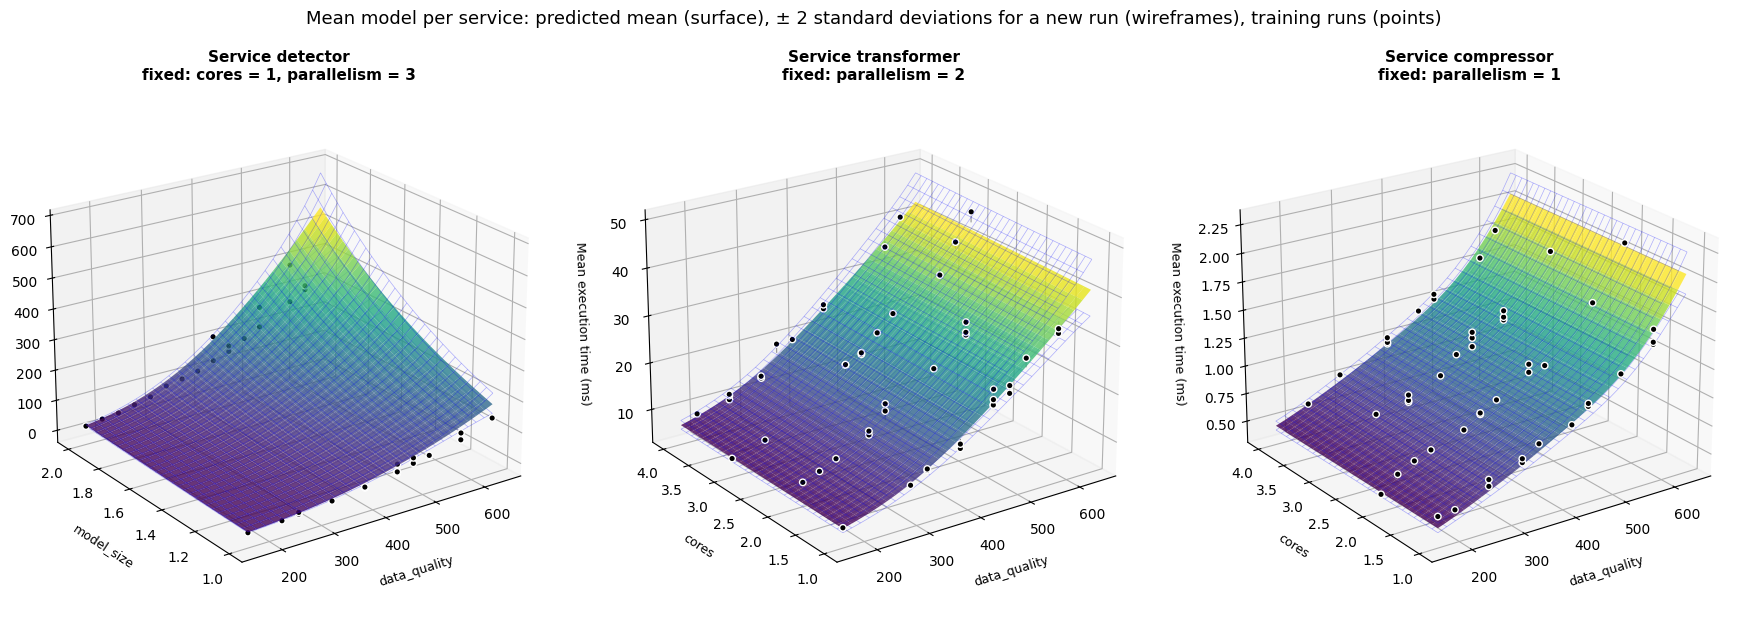

In [5]:
# Mean model of every service over two of its knobs (configuration_grid in pegasus/real_data.py); the other knobs are fixed
# at their most frequent value in the held-out runs
surface_knobs = {"detector": ("data_quality", "model_size"), "transformer": ("data_quality", "cores"), "compressor": ("data_quality", "cores")}
knob_names = feature_names(experiment)   # per service: the names of the columns of its configurations
fig = plt.figure(figsize=(18, 6), dpi=100)
for idx, s_name in enumerate(service_names, 1):
    knob_a, knob_b = surface_knobs[s_name]
    grid_a, grid_b, x_grid, fixed = configuration_grid(X_train[s_name], knob_names[s_name], knob_a, knob_b, x_fixed=X_cfg_test[s_name])
    model = gp_models[s_name]
    surface = lambda shift: 1e3 * model.mean(x_grid, shift).reshape(grid_a.shape)   # ms
    ax = fig.add_subplot(1, 3, idx, projection='3d')
    ax.plot_surface(grid_a, grid_b, surface(0.0), cmap='viridis', alpha=0.8, edgecolor='none')
    ax.plot_wireframe(grid_a, grid_b, surface(+2.0), color='blue', linewidth=0.5, alpha=0.3)
    ax.plot_wireframe(grid_a, grid_b, surface(-2.0), color='blue', linewidth=0.5, alpha=0.3)

    # training runs: their run means, with the residual to the model's prediction at their own configuration
    train_a, train_b = X_train[s_name][:, knob_names[s_name].index(knob_a)], X_train[s_name][:, knob_names[s_name].index(knob_b)]
    observed, predicted = 1e3 * y_train_dict[s_name], 1e3 * model.mean(X_train[s_name])
    for x_a, x_b, y_o, y_p in zip(train_a, train_b, observed, predicted):
        ax.plot([x_a, x_a], [x_b, x_b], [y_p, y_o], color='black', alpha=0.4, linewidth=0.8)
    ax.scatter(train_a, train_b, observed, color='black', s=22, edgecolors='white', alpha=1.0, zorder=10)

    ax.set_title(f"Service {s_name}\nfixed: " + ", ".join(f"{name} = {value:g}" for name, value in fixed.items()), fontsize=11, fontweight='bold')
    ax.set_xlabel(knob_a, fontsize=9, labelpad=8)
    ax.set_ylabel(knob_b, fontsize=9, labelpad=8)
    ax.set_zlabel("Mean execution time (ms)", fontsize=9, labelpad=8)
    ax.view_init(elev=22, azim=-125)
plt.suptitle("Mean model per service: predicted mean (surface), ± 2 standard deviations for a new run (wireframes), training runs (points)",
             fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

### 3b. Effect of the Cores per Worker

Section 3 fixes the number of workers (`parallelism`) at its most frequent value among the held-out runs. A service with $w$ workers and $c$ CPU cores shares the
$c$ cores among its $w$ workers, so the number of *cores per worker* $c / w$ is the share of the CPU that one item gets
while it is processed. This figure shows how the mean model of every service responds to the resolution and to that
ratio, and whether the ratio alone matters or also how it is reached (one worker on one core versus four workers on four
cores).

Every panel is one service. The first horizontal axis is the resolution (`data_quality`, in pixels); the second is the
number of cores per worker $c / w$, on a logarithmic scale (the axis shows $c / w$, the surfaces are drawn over
$\log_2(c / w)$); the vertical axis is the predicted mean execution time (ms). Every surface is one number of workers $w$
from one to four: the cores $c$ vary over their training range (one to four), so the surface with $w$ workers spans
the ratios $1/w$ to $4/w$. The only fixed knob is the model size of the object detector (`model_size`), at its lower
value, the smaller model. The points are the training runs with that model size, at their resolution and their cores
per worker, in the color of their number of workers; a vertical line connects each of them to the model's prediction
at the configuration of that run, as in Section 3. The ± 2 standard deviation wireframes of Section 3 are left out,
since four surfaces per panel would hide them.

If only the ratio mattered, the surfaces of all worker counts would lie on one surface where they overlap. A surface
that lies above another at the same ratio means that more workers on proportionally more cores make a single item
slower, e.g. because the workers compete for memory.

/tmp/ipykernel_187021/1561648728.py:53: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


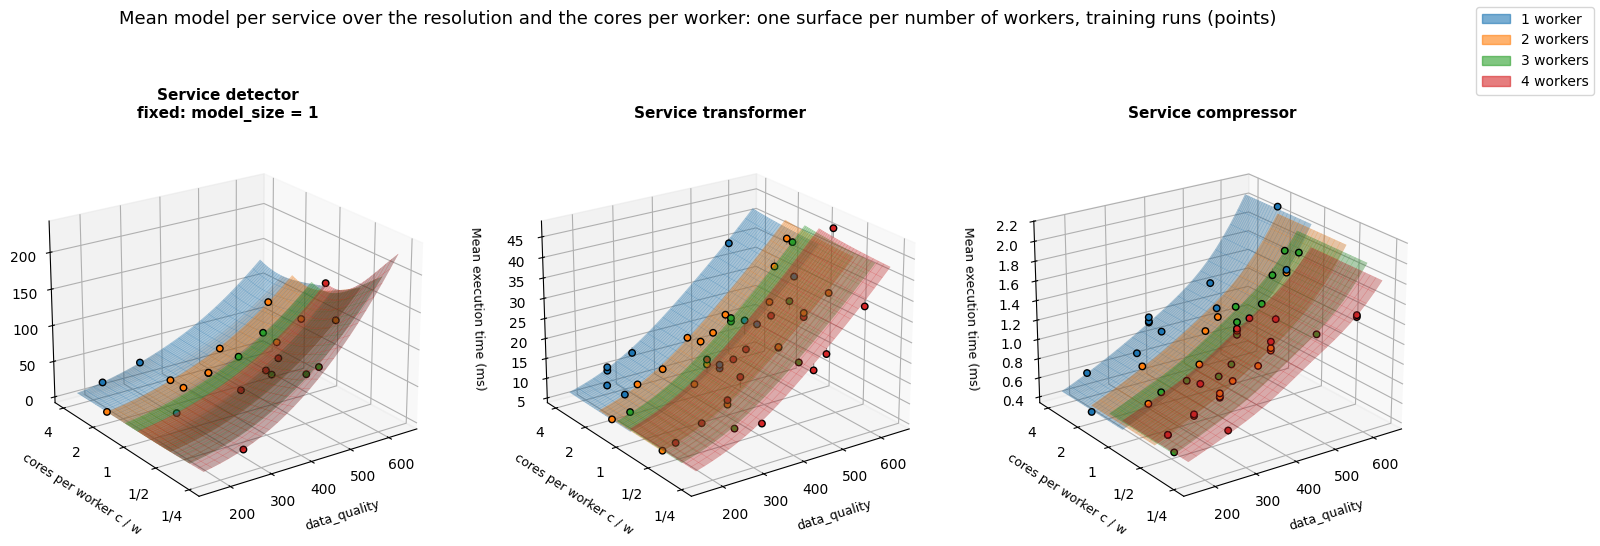

In [6]:
# Mean model of every service over the resolution and the cores per worker (cores / parallelism), one surface per number of
# workers; the detector is fixed at its smaller model, every other knob varies
ratio_fixed = {"model_size": 1.0}   # knob -> fixed value, for the services that have the knob
worker_counts = [1, 2, 3, 4]        # the numbers of workers of the training runs
worker_colors = dict(zip(worker_counts, ["tab:blue", "tab:orange", "tab:green", "tab:red"]))
cores_effect, same_ratio_change = {}, {}   # per service, for the conclusion below
fig = plt.figure(figsize=(18, 6), dpi=100)
for idx, s_name in enumerate(service_names, 1):
    names, model = knob_names[s_name], gp_models[s_name]
    c, p, q = names.index("cores"), names.index("parallelism"), names.index("data_quality")
    base = configuration_grid(X_train[s_name], names, "cores", "data_quality", n_grid=1, x_fixed=X_cfg_test[s_name])[2][0]
    for name, value in ratio_fixed.items():
        if name in names:
            base[names.index(name)] = value
    grid_q, grid_c = np.meshgrid(np.linspace(X_train[s_name][:, q].min(), X_train[s_name][:, q].max(), 25),
                                 np.linspace(X_train[s_name][:, c].min(), X_train[s_name][:, c].max(), 25))
    ax = fig.add_subplot(1, 3, idx, projection='3d')
    surfaces = {}
    for workers in worker_counts:
        x = np.tile(base, (grid_q.size, 1))
        x[:, q], x[:, c], x[:, p] = grid_q.ravel(), grid_c.ravel(), workers
        surfaces[workers] = 1e3 * model.mean(x).reshape(grid_q.shape)   # ms
        ax.plot_surface(grid_q, np.log2(grid_c / workers), surfaces[workers], color=worker_colors[workers], alpha=0.35,
                        edgecolor=worker_colors[workers], linewidth=0.2)

    # training runs with the fixed knobs, with the residual to the model's prediction at their own configuration
    x_run = X_train[s_name]
    keep = np.all([x_run[:, names.index(name)] == value for name, value in ratio_fixed.items() if name in names], axis=0) \
        if any(name in names for name in ratio_fixed) else np.ones(len(x_run), dtype=bool)
    observed, predicted = 1e3 * y_train_dict[s_name][keep], 1e3 * model.mean(x_run[keep])
    run_q, run_r, run_w = x_run[keep, q], np.log2(x_run[keep, c] / x_run[keep, p]), x_run[keep, p]
    for x_q, x_r, y_o, y_p in zip(run_q, run_r, observed, predicted):
        ax.plot([x_q, x_q], [x_r, x_r], [y_p, y_o], color='black', alpha=0.4, linewidth=0.8)
    ax.scatter(run_q, run_r, observed, c=[worker_colors[int(w)] for w in run_w], s=22, edgecolors='black', alpha=1.0, zorder=10)

    # how much the cores move the prediction at fixed workers, and the workers at one core per worker (over all resolutions)
    cores_effect[s_name] = max((surface.max(axis=0) / surface.min(axis=0)).max() for surface in surfaces.values())
    one_per_worker = [np.argmin(np.abs(grid_c[:, 0] - workers)) for workers in worker_counts]   # grid row with c = w
    same_ratio_change[s_name] = surfaces[worker_counts[-1]][one_per_worker[-1]] / surfaces[worker_counts[0]][one_per_worker[0]]

    fixed = {name: value for name, value in ratio_fixed.items() if name in names}
    ax.set_title(f"Service {s_name}" + ("\nfixed: " + ", ".join(f"{name} = {value:g}" for name, value in fixed.items()) if fixed else ""),
                 fontsize=11, fontweight='bold')
    ax.set_xlabel("data_quality", fontsize=9, labelpad=8)
    ax.set_ylabel("cores per worker c / w", fontsize=9, labelpad=8)
    ax.set_yticks(np.log2([0.25, 0.5, 1, 2, 4]), ["1/4", "1/2", "1", "2", "4"])
    ax.set_zlabel("Mean execution time (ms)", fontsize=9, labelpad=8)
    ax.view_init(elev=22, azim=-125)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=worker_colors[w], alpha=0.6) for w in worker_counts],
           labels=[f"{w} worker{'s' * (w > 1)}" for w in worker_counts], loc="upper right", fontsize=10)
plt.suptitle("Mean model per service over the resolution and the cores per worker: one surface per number of workers, training runs (points)",
             fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

In [7]:
no_cores_effect = 1.01   # a service whose prediction changes by less than 1% with the cores at fixed workers counts as ignoring the cores
cfs_period = 0.1          # s, the scheduling period in which Docker enforces the CPU quota `cpus` of a container (its default)
ignores_cores = [s_name for s_name in service_names if cores_effect[s_name] < no_cores_effect]
uses_cores = [s_name for s_name in service_names if s_name not in ignores_cores]
listed = lambda values, fmt, nodes=service_names: ", ".join(f"{fmt(values[s_name])} ({s_name})" for s_name in nodes)
spread = lambda values: f"{ratio(np.min(values))} to {ratio(np.max(values))}"
busy_share = {s_name: np.median(shares) for s_name, shares in training_busy_worker_shares(experiment, split[0]).items()}
quarter_quota = 0.25 * cfs_period   # s of CPU time per period at 1/4 core, the smallest cores per worker of the training runs
below_quota = {s_name: np.mean(y_train_dict[s_name] < quarter_quota) for s_name in service_names}
both = lambda nodes: " and ".join(nodes)
display(Markdown(
    f"**What this shows.** At a fixed number of workers and resolution, the cores change the predicted mean execution time by "
    f"at most a factor of {listed(cores_effect, ratio)}. "
    + (f"For {both(ignores_cores)}, the surfaces are flat along the cores per worker: the model has learned no effect "
       "of the cores, and the surfaces differ only by the number of workers. " if ignores_cores else "")
    + f"At one core per worker, going from one to four workers changes the predicted mean by a factor of {listed(same_ratio_change, spread)} "
    "(over the resolutions of the plot); a factor of 1 would mean that only the ratio matters."
    + ("\n\n**Why the cores barely matter here.** The flat surfaces come from the load of the training runs, not from the "
       "services: the resources do have an effect, but these runs never reach it. Two things keep a request from feeling "
       "the cores per worker. First, the cores per worker are the share of the CPU a request gets only if all workers are "
       "busy at once. The object detector is first in the chain and much slower than the services after it, so it spaces "
       "the requests out. In the median training run, the share of requests that arrived while another worker of their "
       f"service was busy is {listed(busy_share, pct, ignores_cores)}, against {listed(busy_share, pct, uses_cores)}. "
       "A request at those services usually has all cores of the container to itself, however many workers share them. "
       "Second, the cores are a CPU-time quota (`cpus` in the `compose.yaml` of every run), which Docker enforces per "
       f"scheduling period of {cfs_period * 1e3:g} ms: at the smallest ratio of the training runs, a quarter core per worker, "
       f"a container may still use {quarter_quota * 1e3:g} ms of CPU time per period and worker. A request that needs less "
       "than that finishes before the quota throttles it; the mean execution time of a training run lies below that budget "
       f"in {listed(below_quota, pct, ignores_cores)} of the runs. The flat surfaces therefore hold for this chain and load "
       f"only: the training runs contain no configuration in which the cores limit {both(ignores_cores)}, so the model "
       "cannot predict one, e.g. at a higher load or without the slow detector in front." if ignores_cores and uses_cores else "")
    + f"\n\nThe held-out runs, at which the bounds of Sections 6 and 7 are evaluated, have "
    f"{min(w.min() for w in workers_by_service.values())} to {max(w.max() for w in workers_by_service.values())} workers per "
    "service, so every surface is used."))

**What this shows.** At a fixed number of workers and resolution, the cores change the predicted mean execution time by at most a factor of 1.62× (detector), 1.04× (transformer), 1.00× (compressor). For compressor, the surfaces are flat along the cores per worker: the model has learned no effect of the cores, and the surfaces differ only by the number of workers. At one core per worker, going from one to four workers changes the predicted mean by a factor of 1.01× to 1.04× (detector), 1.10× to 1.12× (transformer), 0.89× to 1.20× (compressor) (over the resolutions of the plot); a factor of 1 would mean that only the ratio matters.

**Why the cores barely matter here.** The flat surfaces come from the load of the training runs, not from the services: the resources do have an effect, but these runs never reach it. Two things keep a request from feeling the cores per worker. First, the cores per worker are the share of the CPU a request gets only if all workers are busy at once. The object detector is first in the chain and much slower than the services after it, so it spaces the requests out. In the median training run, the share of requests that arrived while another worker of their service was busy is 0% (compressor), against 67% (detector), 16% (transformer). A request at those services usually has all cores of the container to itself, however many workers share them. Second, the cores are a CPU-time quota (`cpus` in the `compose.yaml` of every run), which Docker enforces per scheduling period of 100 ms: at the smallest ratio of the training runs, a quarter core per worker, a container may still use 25 ms of CPU time per period and worker. A request that needs less than that finishes before the quota throttles it; the mean execution time of a training run lies below that budget in 100% (compressor) of the runs. The flat surfaces therefore hold for this chain and load only: the training runs contain no configuration in which the cores limit compressor, so the model cannot predict one, e.g. at a higher load or without the slow detector in front.

The held-out runs, at which the bounds of Sections 6 and 7 are evaluated, have 1 to 4 workers per service, so every surface is used.

## 4. Visualization: Coverage Analysis of the GP (Test Dataset)

This section checks step 1 only: whether a single *execution time* falls below the model's predictive quantile
$\mu + z\sigma$, with $\mu$ from the mean model and $\sigma$ from the spread model. It is not a check of the latency
bound, which also includes queueing; that check is in Section 6f.

The test data are the execution times (processing time plus handling overhead, Section 1a) that the testbed measured
for every request in the runs of the evaluated chain: none of these runs was used for training. Every panel shows the
measured execution times of one service, sorted, on a logarithmic axis (s), and the predictive quantile of the run that
each of them belongs to. The title gives the *coverage*, the share of the measured execution times that lie below the
quantile; the target is $1-\varepsilon$.

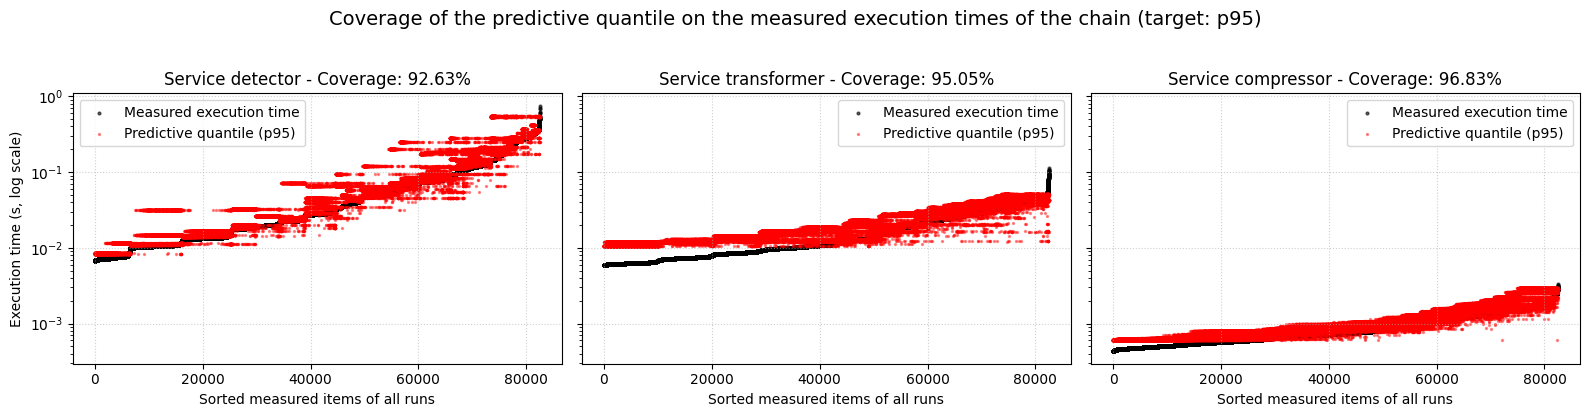

In [8]:
# Measured execution times of every run of the chain (requests, services), and the predictive quantile of every run
test_times = chain_run_execution_times(experiment, split[1])
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
quantile_ratio = {}       # per service: predictive quantile ÷ measured execution time, for every measured item (Section 5)
coverage_by_service = {}  # per service: share of the measured execution times below the predictive quantile
for k, (ax, s_name) in enumerate(zip(axes, service_names)):
    mu_test, std_test = gp_models[s_name].predict(X_cfg_test[s_name], return_std=True)   # one prediction per run
    y_true_test = np.concatenate([run_times[:, k] for run_times in test_times])
    upper_bound = np.concatenate([np.full(len(run_times), mu + z_score * std) for run_times, mu, std in zip(test_times, mu_test, std_test)])
    quantile_ratio[s_name] = upper_bound / y_true_test
    coverage_by_service[s_name] = np.mean(y_true_test <= upper_bound)

    sort_idx = np.argsort(y_true_test)
    ax.scatter(range(len(y_true_test)), y_true_test[sort_idx], color='black', alpha=0.6, s=4, label="Measured execution time")
    ax.scatter(range(len(y_true_test)), upper_bound[sort_idx], color='red', s=2, alpha=0.4, label=f"Predictive quantile (p{p_str})")
    ax.set_yscale("log")
    ax.set_title(f"Service {s_name} - Coverage: {coverage_by_service[s_name]:.2%}")
    ax.set_xlabel("Sorted measured items of all runs")
    if k == 0:
        ax.set_ylabel("Execution time (s, log scale)")
    ax.legend()
    ax.grid(True, linestyle=":", alpha=0.6)

plt.suptitle(f"Coverage of the predictive quantile on the measured execution times of the chain (target: p{p_str})", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

## 5. Visualization: GP Tightness Analysis

Tightness of the predictive quantile against single execution times: the predictive quantile ÷ the measured execution
time, for every measured item of Section 4. The synthetic notebook shows the difference in seconds; the execution
times differ by more than an order of magnitude between configurations and between services, so the ratio is shown
instead. A
ratio of 1 is exact, larger is looser, and a ratio below 1 is an item above the quantile. The horizontal axis is
logarithmic; the legend gives the median ratio of every service.

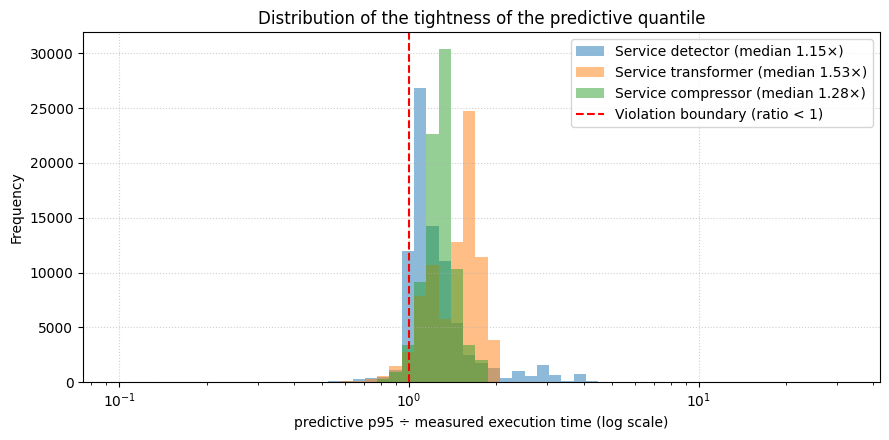

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.logspace(-1, 1.5, 60)
for s_name in service_names:
    ax.hist(quantile_ratio[s_name], bins=bins, alpha=0.5, label=f"Service {s_name} (median {np.median(quantile_ratio[s_name]):.2f}×)")
ax.axvline(1, color='red', linestyle='--', linewidth=1.5, label="Violation boundary (ratio < 1)")
ax.set_xscale("log")
ax.set_title("Distribution of the tightness of the predictive quantile", fontsize=12)
ax.set_xlabel(f"predictive p{p_str} ÷ measured execution time (log scale)")
ax.set_ylabel("Frequency")
ax.legend()
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

In [10]:
# Why a service misses the target in Section 4: the error of the predicted run mean against the scatter of single items
mean_error, item_scatter = {}, {}   # per service: median over the runs, both relative to the measured run mean
for k, s_name in enumerate(service_names):
    run_means = np.array([run_times[:, k].mean() for run_times in test_times])
    mean_error[s_name] = np.median(np.abs(gp_models[s_name].mean(X_cfg_test[s_name]) / run_means - 1))
    item_scatter[s_name] = np.median([run_times[:, k].std() / run_times[:, k].mean() for run_times in test_times])
short = [s_name for s_name in service_names if coverage_by_service[s_name] < 1 - alpha]
detail = lambda s_name: f"{s_name}: mean off by {mean_error[s_name]:.1%}, items scatter by {item_scatter[s_name]:.1%}"
display(Markdown(
    f"**What Sections 4 and 5 show.** Coverage of the predictive p{p_str} of the execution time (target {pct(1 - alpha)}): "
    + ", ".join(f"{s_name} {coverage_by_service[s_name]:.1%}" for s_name in service_names) + ".\n"
    + (f"- **Below the target: {', '.join(short)}.** The predictive quantile adds the scatter of single items to the "
       "predicted mean, but not the error of the predicted mean itself. Per service, the median relative error of the "
       "predicted run mean and the median standard deviation of single items, both relative to the measured run mean: "
       + "; ".join(detail(s_name) for s_name in service_names) + ". Where the error of the mean is larger than the scatter "
       "of the items, nearly every item of a run whose mean is underpredicted lies above the quantile. The latency bounds "
       "of Section 6 add the uncertainty about the mean (the pessimistic mean of 6b); this check of single execution "
       "times does not.\n" if short else "- **Every service reaches the target.**\n")
    + "- **Tightness (Section 5):** the median of predictive quantile ÷ execution time is "
    + ", ".join(f"{ratio(np.median(quantile_ratio[s_name]))} for {s_name}" for s_name in service_names) + "."))


**What Sections 4 and 5 show.** Coverage of the predictive p95 of the execution time (target 95%): detector 92.6%, transformer 95.1%, compressor 96.8%.
- **Below the target: detector.** The predictive quantile adds the scatter of single items to the predicted mean, but not the error of the predicted mean itself. Per service, the median relative error of the predicted run mean and the median standard deviation of single items, both relative to the measured run mean: detector: mean off by 3.6%, items scatter by 5.5%; transformer: mean off by 3.8%, items scatter by 16.6%; compressor: mean off by 3.8%, items scatter by 11.6%. Where the error of the mean is larger than the scatter of the items, nearly every item of a run whose mean is underpredicted lies above the quantile. The latency bounds of Section 6 add the uncertainty about the mean (the pessimistic mean of 6b); this check of single execution times does not.
- **Tightness (Section 5):** the median of predictive quantile ÷ execution time is 1.15× for detector, 1.53× for transformer, 1.28× for compressor.

## 6. Node Bounds: the Latency of One Service

A node bound is a latency $d$ of one service that is exceeded with probability at most $\varepsilon$. All node bounds start
from the prediction of the execution time $X$ (Section 2): its mean $\mu(x)$, its variance $\sigma^2(x)$, and the closed-form
Moment Generating Function (MGF) $M_X(\theta) = \mathbb{E}[e^{\theta X}] = \exp\left(\theta \mu + \frac{\theta^2}{2}\sigma^2\right)$.
The section is structured as follows:

- **6a. Execution-time bound (baseline):** Chernoff's inequality on one execution time, without a queue.
- **6b. SNC queueing bound:** the latency at a FIFO server with renewal arrivals, from a union bound over queue lengths
  and Chernoff's inequality, with the GP's predictive distribution as the belief about the execution time.
- **6c. Propagated arrival models:** the SNC bound for a node that receives the departures of the node before it.
- **6d. Martingale bound:** a bound on the waiting time from an exponential martingale, without the Chernoff step.
- **6e. Martingale bound with propagated service spacing:** the martingale bound for a node that receives the
  departures of the node before it (6c and 6d combined).
- **6f. Node bounds on held-out configurations (RQ1):** coverage and tightness against the measured latency of every
  service in the chain.

The arrival rate $\lambda$ is the one of the run (Section 1b), so it differs between the held-out configurations.
The cell below sets up the evaluation of 6f (held-out configurations and the measured latencies of every service);
each subsection then computes its node bound directly after its explanation.

In [11]:
# Setup of the evaluation in 6f: the measured latency of every service of the chain in every run (ground truth), and the
# belief about the execution time (run_statistics_belief in pegasus/service_gp.py: the mean shift of 6b).
# Every subsection below adds its node bound to node_bounds.
run_latencies = chain_run_latencies(experiment, split[1])   # per held-out run: end-to-end latencies, latencies per service, arrival times per service
measured_by_service, measured_low_by_service, beliefs, node_bounds = {}, {}, {}, {}
for k, s_name in enumerate(service_names):
    measured_by_service[s_name], measured_low_by_service[s_name] = measured_quantiles([node[:, k] for _, node, _ in run_latencies], 1 - alpha,
                                                                                                  coverage_check)
    beliefs[s_name] = run_statistics_belief(gp_models[s_name], X_cfg_test[s_name], confidence)
    node_bounds[s_name] = {}
print("Setup of Section 6 ready.")

Setup of Section 6 ready.


### 6a. Execution-Time Bound (Baseline)

Chernoff's inequality $P(X \ge D) \le M_X(\theta)\,e^{-\theta D}$, optimized over $\theta$, gives
$D = \mu + \sigma\sqrt{2\ln(1/\varepsilon)}$. It ignores the arrival rate $\lambda$ and the queue, so it is not a bound on
latency; it is kept as the baseline "Chernoff only execution" (`compute_snc_mgf_delay_bound` in `pegasus/baselines_chain.py`).

In [12]:
# Execution-time bound (baseline; compute_snc_mgf_delay_bound in pegasus/baselines_chain.py)
for s_name in service_names:
    node_bounds[s_name]["Chernoff only execution (6a)"] = compute_snc_mgf_delay_bound(gp_models[s_name], X_cfg_test[s_name], alpha=alpha)[0]

### 6b. SNC Queueing Bound

An item's latency $W$ at a FIFO server is the largest backlog it finds:
$W = \max_{n \ge 0}\left(\sum_{i=0}^{n} X_i - \sum_{i=1}^{n} T_i\right)$, where the $X_i$ are the execution times of the item and the
$n$ items before it, and the $T_i$ are inter-arrival times. A union bound over $n$ and Chernoff's inequality for each
term give

$$P(W > d) \;\le\; e^{-\theta d}\,\frac{M_X(\theta)}{1 - \rho(\theta)}, \qquad \rho(\theta) = M_X(\theta)\,\mathbb{E}[e^{-\theta T}] < 1,$$

which holds for any i.i.d. inter-arrival times. For Poisson arrivals $\mathbb{E}[e^{-\theta T}] = \lambda / (\lambda + \theta)$;
for periodic arrivals with gaps $T = \frac{1}{\lambda}(1 + U)$, $U \sim \mathcal{U}(-j, j)$, it is
$\mathbb{E}[e^{-\theta T}] = e^{-\theta a}\,\frac{1 - e^{-\theta w}}{\theta w}$ with $a = (1 - j)/\lambda$ and $w = 2j/\lambda$
($e^{-\theta/\lambda}$ for $j = 0$). The latency bound at violation probability $\varepsilon$ is the best $\theta$:
$\;d(\varepsilon) = \min_\theta \frac{1}{\theta}\left[\ln M_X(\theta) - \ln(1 - \rho(\theta)) - \ln \varepsilon\right]$.
For $\lambda \to 0$, $\rho \to 0$ and this is exactly the execution-time bound of 6a, its special case of an empty queue.
If $\rho(\theta) \ge 1$ for every $\theta$ (the service is overloaded) there is no finite bound.

**Services with several workers.** A service with $w$ workers (`parallelism`) takes the items in the order of arrival
and gives each to the first free worker. Its waiting time is at most the waiting time under *cyclic assignment*, where
every $w$-th item goes to the same worker (Wolff, "An upper bound for multi-channel queues", J. Appl. Prob. 1977).
Under cyclic assignment every worker is a single-server FIFO queue whose gap between two arrivals is the sum of $w$
consecutive gaps $T$; for i.i.d. gaps, $\mathbb{E}[e^{-\theta T}]$ becomes $\mathbb{E}[e^{-\theta T}]^w$, so
$\rho(\theta) = M_X(\theta)\,\mathbb{E}[e^{-\theta T}]^w$. For example, Poisson arrivals at $\lambda$ = 10 items/s and
$w = 2$ workers give $\rho(\theta) = M_X(\theta)\,\big(10 / (10 + \theta)\big)^2$: every worker sees on average one item
every 0.2 s instead of every 0.1 s. Every node bound of this section and every composition of Section 7 uses this
factor with the workers of the service in the run; with one worker it is the single-server bound above
(`bounds.py`, module docstring). The bound is looser than the true wait with $w$ workers, because under cyclic
assignment an item can wait at its worker while another worker is idle.

**Belief about the execution time (epistemic mean shift).** The GP's error about the mean execution time at a
configuration (its epistemic uncertainty $\sigma_{\text{ep}}^2(x)$) is shared by every item at that configuration: if the
GP underestimates the mean by 5 ms, every item is 5 ms slower, and in a busy period of $n$ items the work grows by
$n \times$ 5 ms. The scatter of individual items (aleatoric, $\sigma_{\text{al}}^2$) is independent from item to item and
partly averages out. Every bound therefore uses a pessimistic mean and only the aleatoric variance per item:
$\mu^+(x) = \mu(x) + z_c\,\sigma_{\text{ep}}(x)$, where $z_c$ is the standard-normal quantile at the confidence level $c$
(`confidence` in the first cell), so the true mean lies below $\mu^+$ with probability $c$.

**With the two models of Section 2** (`run_statistics_belief` in `pegasus/service_gp.py`), $\sigma_{\text{ep}}(x)$ is the
predictive standard deviation of the mean model: its uncertainty about the mean function and the scatter between runs
at the same configuration, both of which are shared by all items of a run. The mean model works on the logarithm, so
the shift is relative: $\mu^+(x) = \mu(x)\,e^{z_c \sigma_{\text{ep}}(x)}$ with $\sigma_{\text{ep}}$ on the logarithm. $\sigma_{\text{al}}(x)$ is the prediction of
the spread model. The spread has no margin of its own: where the spread model predicts too small a scatter, the bound
is too small.

In [13]:
# SNC queueing bound (snc_latency_bound in pegasus/bounds.py)
for s_name in service_names:
    node_bounds[s_name]["SNC (6b)"] = snc_latency_bound(*beliefs[s_name], epsilon=alpha, workers=workers_by_service[s_name], **workload)

### 6c. Node Bound with Propagated Arrival Models

The SNC bound (6b) assumes that its node receives the *external* arrivals. That is true for the first
node only: node $k \ge 2$ receives the departures of node $k-1$. The propagated node bound bounds those departures instead
of reusing the external arrival process. It is composed with the union bound like the other node bounds (Section 7a)
(`propagated_node_bounds` in `pegasus/bounds.py`).

Let $A_n$ be the time between the arrivals of item $i-n$ and item $i$ at node $k$, i.e. between their departures from
node $k-1$. Write $X'$ for execution times and $W'$ for latencies at node $k-1$, and $A'_n$ for the same span at the
*input* of node $k-1$. Two lower bounds hold on every sample path:

1. **Service spacing:** node $k-1$ serves one item at a time, so $A_n \ge X'_{i-n+1} + \dots + X'_i$.
2. **Arrival spacing:** item $i$ leaves node $k-1$ no earlier than its arrival plus its execution time, and item
   $i-n$ leaves exactly at its arrival plus its latency, so $A_n \ge A'_n + X'_i - W'_{i-n}$.

Hence $\mathbb{E}[e^{-\theta A_n}] \le \min\big(M_{X'}(-\theta)^n,\; \mathbb{E}[e^{-\theta A'_n}]\,M_{X'}(-\theta)\,\mathbb{E}[e^{\theta W'}],\; \mathbb{E}[e^{-\theta T}]^n,\; 1\big)$.
The third term is the external arrival process, which the SNC bound (6b) assumes at every node; with it, the propagated
bound is never looser than the SNC bound. In the other two terms,
$\mathbb{E}[e^{\theta W'}]$ is the moment that node $k-1$'s own bound already computes. Wherever node $k-1$'s execution times space the items
(the terms with $M_{X'}(-\theta)$), node $k-1$ enters with its optimistic mean $\mu'^- = \mu' - z_c\,\sigma'_{\text{ep}}$, because a
faster node spaces items less; its latency moment keeps the pessimistic mean of 6b. Node $k$'s bound is the
union/Chernoff sum of Section 6b with this spacing in place of the external one:
$P(W > d) \le e^{-\theta d} \sum_n M_X(\theta)^{n+1}\,\mathbb{E}[e^{-\theta A_n}]$.

Bound 1 removes the double counting: a node behind a slower node almost never queues, and its bound now reflects
that. Bound 2 carries the external arrival rate along the chain; it is needed where a node is slower than the node
before it.

**Assumptions (beyond those of the SNC bound, which the third term uses):**
- A node's execution times are independent of the spacing of its arrivals. For bound 1, positive correlation between
  an item's execution times at consecutive nodes makes this conservative: the difference of two positively
  correlated Gaussians has a smaller variance than that of two independent ones.
- The latency of item $i-n$ at node $k-1$ is independent of the arrival spacing after it. This is exact directly
  behind the external source (renewal arrivals) and an assumption further down. `2_evaluation.ipynb` tests it by the
  coverage of the composed bound.

**Several workers.** A worker of node $k$ with $w_k$ workers receives every $w_k$-th item (cyclic assignment, 6b), so
the spacing of its arrivals is $A_{n w_k}$ instead of $A_n$. Bounds 1 and 2 need node $k-1$ to release the items one at
a time and in order, which holds only if node $k-1$ has one worker: with several workers, items overtake each other and
can leave almost at once. Behind a node with several workers, node $k$ therefore assumes the external arrival process
(the third term).

A single service has no upstream node, so there the propagated bound equals the SNC bound of 6b; it is computed on
chains in Section 7a.

### 6d. Martingale Node Bound

With Poisson arrivals, the SNC bound (6b) is loose mainly because of its last step: a Chernoff bound with
one $\theta$, which pays $\ln(1/\varepsilon)/\theta$ and a factor $1/(1-\rho(\theta))$ and cannot use that most items don't wait.
With periodic arrivals, $\theta$ is not capped and both terms are small (see `explain_2_why_poisson_is_loose.ipynb`). The martingale bound replaces that step. Every node assumes the external arrival process, exactly like the SNC bound.
It is composed with the union bound like the other node bounds (Section 7a) (`martingale_node_bound` in
`pegasus/bounds.py`).

Write $Q$ for the waiting time of an item at a node (latency minus its own execution time $X$), $T$ for the gap
between arrivals, and $\theta^*$ for the decay rate of the waiting-time tail, the largest $\theta$ with
$\rho(\theta) = M_X(\theta)\,\mathbb{E}[e^{-\theta T}] \le 1$.

1. **Waiting time, any renewal arrivals (Kingman's martingale bound):** $e^{\theta^* (X_1 - T_1 + \dots + X_n - T_n)}$ is a
   martingale over $n$, which gives $P(Q > w) \le e^{-\theta^* w}$. Unlike Section 6b there is no sum over $n$ and no
   $1/(1-\rho)$ factor.
2. **Waiting time, Poisson arrivals (refinement):** by Pollaczek–Khinchine, $Q$ is 0 with probability $1-\rho$ and
   otherwise a sum of residual execution times. Splitting off the first of them and applying step 1 to the rest gives
   $P(Q > w) \le \lambda \int_0^\infty P(X > x)\,\min\big(1, e^{-\theta^*(w - x)}\big)\,dx$, which is at most $\rho$ at
   $w = 0$: the bound now starts at the share of items that wait, not at 1.
3. **Latency:** $Q$ depends only on earlier items, so it is independent of the item's own $X$, and
   $P(Q + X > d) = \mathbb{E}_X\big[P(Q > d - X)\big]$ is computed directly (no second Chernoff step). The expectation is
   evaluated on equal-probability bins of $X$ at each bin's upper edge, with the last bin counted as a violation, so
   the discretization can only make the bound larger.

$\theta^*$ is taken from the same $\theta$ grid as Section 6b, as the largest grid value below the first crossing of
$\rho(\theta) = 1$; any $\theta \le \theta^*$ keeps both bounds valid. $X$ is the same belief as for the SNC bound
(the epistemic mean shift of 6b).

**Assumptions:** the same as the SNC bound (every node sees the external arrival process), plus renewal arrivals for step 1
and Poisson arrivals for step 2. For periodic arrivals, only step 1 is used. A node with several workers uses step 1
with $\rho(\theta)$ of 6b for $w$ workers and no step 2: a worker receives every $w$-th item (cyclic assignment), which is
not a Poisson stream.

In [14]:
# Martingale bound (martingale_node_bound in pegasus/bounds.py)
for s_name in service_names:
    node_bounds[s_name]["martingale (6d)"] = martingale_node_bound(*beliefs[s_name], epsilon=alpha, workers=workers_by_service[s_name], **workload)

### 6e. Martingale Bound with Propagated Service Spacing

The martingale bound of 6d assumes the external arrival process at every node. A node $k \ge 2$, however, receives the
departures of node $k-1$, which cannot be closer together than node $k-1$'s execution times (bound 1 of 6c). The waiting
time at node $k$ is then at most the maximum of a random walk with increments $X_{k,j} - X'_{j+1}$: an execution time at
node $k$ minus one at node $k-1$. For Gaussian execution times, Kingman's martingale bound (6d, step 1) applies to this walk
with the decay rate $\theta_s = 2(\mu'^- - \mu^+)/(\sigma^2 + \sigma'^2)$, which is large when node $k-1$ is slower. Here
$\mu^+$ is the pessimistic mean of node $k$ (6b), $\mu'^- = \mu' - z_c\,\sigma'_{\text{ep}}$ the optimistic mean of node $k-1$
(a faster node $k-1$ spaces items less), and $\sigma^2, \sigma'^2$ the aleatoric variances. Per node, the bound takes the
smaller of the two waiting-time tails, $\min\big(P_{6d}(Q > w),\, e^{-\theta_s w}\big)$, and adds the own execution time as in
6d (`martingale_propagated_node_bound` in `pegasus/bounds.py`). It is composed with the union bound (Section 7a).

**Several workers.** If node $k$ has $w$ workers, a worker receives items $j$ and $j + w$ (cyclic assignment, 6b), which
node $k-1$ with one worker releases at least $w$ of its execution times apart. The increments are then
$X_{k,j} - (X'_{1} + \dots + X'_{w})$, and $\theta_s = 2(w\,\mu'^- - \mu^+)/(\sigma^2 + w\,\sigma'^2)$. Behind a node with
several workers there is no such spacing (6c), and only the tail of 6d is used.

**Assumptions beyond those of 6d:** consecutive increments share an item but are treated as independent, and an item's
own execution time is treated as independent of its wait (a slow item arrives later and waits less). With positively
correlated execution times of an item, both make the bound conservative; `2_evaluation.ipynb` tests them by the coverage
of the composed bound. Section 6f does not show it; it is composed in Section 7a.

### 6f. Node Bounds on Held-Out Configurations (RQ1)

For every held-out configuration, the measured $(1-\varepsilon)$ latency quantile of each service in the chain (its
waiting plus processing time, at the arrival rate $\lambda$ of the run) is compared with each node bound. *Tightness*
is the median of bound ÷ measured quantile. *Coverage* is the share of configurations that a bound does not miss, where
a configuration counts as missed only if the measurement shows that the bound lies below the true quantile: below the
lower edge of the confidence interval of the measured quantile (`coverage_check` in the first cell; batch means over
consecutive blocks of requests, `measured_quantiles` in `pegasus/real_data.py`). A quantile measured from a few hundred
requests scatters, most at high load, so without the interval a tight bound would be counted as missed by chance. A
valid bound can still miss where the error of the mean model exceeds its confidence band, or where the spread model
predicts too small a scatter.

The first service receives the Poisson arrivals that the node bounds of 6b and 6d assume. A service behind it receives
the departures of the service before it, which are spaced at least by that service's processing times and are usually
less bursty than Poisson arrivals; for it, the Poisson model of 6b and 6d is usually, but not provably, conservative.
The bounds that model these departures (6c, 6e) are composed in Section 7a. The execution-time bound (6a) is included
to show what it misses.

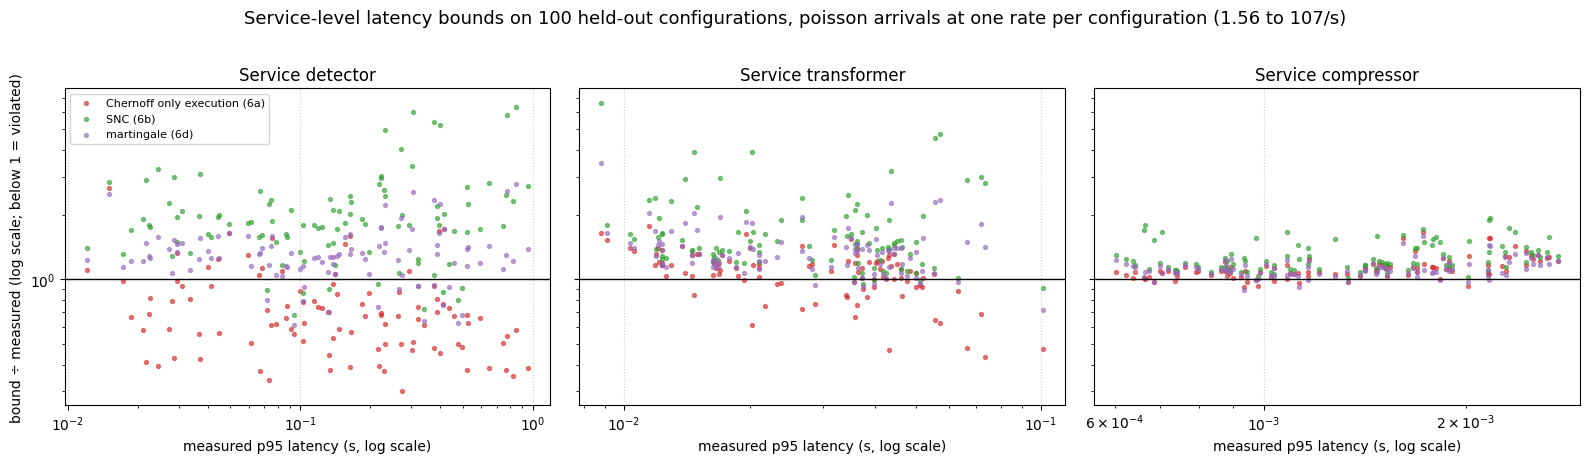

service  bound                               coverage  tightness   finite
detector Chernoff only execution (6a)           29.0%      0.67x     100%
detector SNC (6b)                               99.0%      1.82x     100%
detector martingale (6d)                        93.0%      1.27x     100%
transformer Chernoff only execution (6a)           81.0%      1.12x     100%
transformer SNC (6b)                              100.0%      1.47x     100%
transformer martingale (6d)                        99.0%      1.33x     100%
compressor Chernoff only execution (6a)           97.0%      1.09x     100%
compressor SNC (6b)                              100.0%      1.21x     100%
compressor martingale (6d)                        97.0%      1.10x     100%


In [15]:
# Comparison of the node bounds of 6a, 6b and 6d against the measured latencies of every service in the chain (setup)
bound_names = ["Chernoff only execution (6a)", "SNC (6b)", "martingale (6d)"]   # order of the subsections
single_node_results = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, s_name in zip(axes, service_names):
    measured = measured_by_service[s_name]
    for name, color in zip(bound_names, ["tab:red", "tab:green", "tab:purple"]):
        bound = node_bounds[s_name][name]
        single_node_results[(s_name, name)] = {"coverage": np.mean(bound >= measured_low_by_service[s_name]), "tightness": np.median(bound / measured),
                                               "finite": np.mean(np.isfinite(bound))}
        ax.scatter(measured, bound / measured, s=8, alpha=0.6, color=color, label=name)
    ax.axhline(1.0, color="black", linewidth=1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"Service {s_name}")
    ax.set_xlabel(f"measured p{p_str} latency (s, log scale)")
    ax.grid(True, linestyle=":", alpha=0.6)
axes[0].set_ylabel("bound ÷ measured (log scale; below 1 = violated)")
axes[0].legend(fontsize=8)
plt.suptitle(f"Service-level latency bounds on {n_cfg_test} held-out configurations, {arrivals}", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f"{'service':<8} {'bound':<34} {'coverage':>9} {'tightness':>10} {'finite':>8}")
for (s_name, name), result in single_node_results.items():
    print(f"{s_name:<8} {name:<34} {result['coverage']:>9.1%} {result['tightness']:>9.2f}x {result['finite']:>8.0%}")

In [16]:
across = lambda name, key: [single_node_results[(s_name, name)][key] for s_name in service_names]
misses = [f"{name} at {s_name} (covers {pct(single_node_results[(s_name, name)]['coverage'])})"
          for name in ("SNC (6b)", "martingale (6d)") for s_name in service_names if single_node_results[(s_name, name)]["coverage"] < 1]
display(Markdown(
    f"**What this shows** ({arrivals}). The figure has one panel per service: every point is one held-out configuration, with the "
    f"measured p{p_str} latency of the service in the chain on the horizontal axis and a node bound ÷ that latency on the vertical axis.\n"
    f"- **The execution-time bound (6a) is not a latency bound.** It covers {span(across('Chernoff only execution (6a)', 'coverage'), pct)} "
    "of the configurations per service, because it leaves out the queue.\n"
    f"- **The SNC queueing bound (6b)** covers {span(across('SNC (6b)', 'coverage'), pct)} of the configurations with tightness "
    f"{span(across('SNC (6b)', 'tightness'), ratio)}.\n"
    f"- **The martingale bound (6d)** covers {span(across('martingale (6d)', 'coverage'), pct)} of the configurations with tightness "
    f"{span(across('martingale (6d)', 'tightness'), ratio)}.\n"
    f"- **Finite bounds:** the two latency bounds are finite at {span(across('SNC (6b)', 'finite'), pct)} of the configurations per service. "
    "Where a bound is infinite, the pessimistic mean execution time is so large that the service counts as overloaded at the arrival rate "
    "of the run; such a configuration counts as covered, but the bound says nothing there.\n"
    + ("- **Misses:** a configuration counts as missed only if the measurement shows, at "
       f"{pct(coverage_check['confidence'])} confidence, that the bound lies below the true p{p_str}: " + "; ".join(misses) + ".\n"
       if misses else "- **No misses:** both latency bounds cover every configuration of every service.\n")))

**What this shows** (poisson arrivals at one rate per configuration (1.56 to 107/s)). The figure has one panel per service: every point is one held-out configuration, with the measured p95 latency of the service in the chain on the horizontal axis and a node bound ÷ that latency on the vertical axis.
- **The execution-time bound (6a) is not a latency bound.** It covers between 29% and 97% of the configurations per service, because it leaves out the queue.
- **The SNC queueing bound (6b)** covers between 99% and 100% of the configurations with tightness between 1.21× and 1.82×.
- **The martingale bound (6d)** covers between 93% and 99% of the configurations with tightness between 1.10× and 1.33×.
- **Finite bounds:** the two latency bounds are finite at 100% of the configurations per service. Where a bound is infinite, the pessimistic mean execution time is so large that the service counts as overloaded at the arrival rate of the run; such a configuration counts as covered, but the bound says nothing there.
- **Misses:** a configuration counts as missed only if the measurement shows, at 95% confidence, that the bound lies below the true p95: SNC (6b) at detector (covers 99%); martingale (6d) at detector (covers 93%); martingale (6d) at transformer (covers 99%); martingale (6d) at compressor (covers 97%).


## 7. Composition & End-to-End Performance Analysis

A composition turns the node beliefs of a chain into a bound on its end-to-end latency. Two compositions give a guarantee
that holds for any dependence between the services (7a, 7b); the baselines either assume independence (7c) or have no
tail bound (7f). The section is structured as follows:

- **7a. Union bound:** sums the node bounds of Section 6 (SNC, propagated SNC, martingale, propagated martingale), each
  at violation probability $\varepsilon / K$.
- **7b. Network service curve:** the classical SNC composition: one bound from the concatenated service of all nodes,
  made valid for dependent nodes by Hölder's inequality.
- **7c. Composition by independence (baseline):** combining the node distributions or MGFs directly, valid only for
  independent services.
- **7d, 7e. Deep GP baselines and Fluxion-style composition:** left out for real data, see below.
- **7f. Replay of monitored node latencies (baseline):** the latencies of the chain are built from latencies that were
  monitored at every service on its own, and a regressor predicts their quantile (Geebelen et al., 2014).
- **7g. Reference configuration:** every composition and baseline for one configuration, next to the measured ground
  truth.

The cell below sets up the reference configuration (configuration, node beliefs, measured ground truth); each
subsection then computes its compositions directly after its explanation, and 7g brings them together.
`2_evaluation.ipynb` applies the compositions across configurations, chains and loads.

The *reference configuration* is one run of the chain: among the runs at which every node bound of Section 6 is
finite, the run whose measured end-to-end quantile is the median. A run with an infinite node bound would show nothing
about the compositions; 6f reports how many runs that excludes. The reference configuration is used wherever a single
configuration is shown, and it is not an optimum.

In [17]:
# Setup of Section 7: the reference configuration (one run of the chain), the node beliefs of its three services, and the
# ground truth, the measured latencies of that run (Section 1b).
with_finite_bounds = np.flatnonzero(np.all([np.isfinite(node_bounds[s_name]["SNC (6b)"]) for s_name in service_names], axis=0))
reference = int(with_finite_bounds[np.argsort(data.measured[with_finite_bounds])[len(with_finite_bounds) // 2]])   # median measured quantile among them
reference_rate = float(workload["rate"][reference])                # arrival rate of that run (items/s)
reference_workload = dict(workload, rate=reference_rate)           # passed to every bound at the reference configuration
x_reference = {s_name: X_cfg_test[s_name][[reference]] for s_name in service_names}
reference_workers = [workers_by_service[s_name][[reference]] for s_name in service_names]   # workers of every service in that run
n_nodes = len(service_names)

node_mus, node_stds = [], []
node_beliefs = []  # (pessimistic mean, variance per item): the mean shift of 6b
print(f"Reference configuration: run {reference} of the chain ({len(with_finite_bounds)} of {n_cfg_test} runs have finite node bounds), "
      f"{reference_workload['process']} arrivals at {reference_rate:.3g}/s, workers " + ", ".join(f"{s} {w[0]}" for s, w in zip(service_names, reference_workers)))
print("=== Individual Node Performance Guarantees ===")
for s_name, workers in zip(service_names, reference_workers):
    model = gp_models[s_name]
    mu, std = model.predict(x_reference[s_name], return_std=True)
    # baseline: bound on the execution time only (no queue)
    delay, _, _, _ = compute_snc_mgf_delay_bound(model, x_reference[s_name], alpha=alpha)
    # SNC latency bounds with queueing, at the full budget epsilon and at the union-bound share epsilon / K
    belief = run_statistics_belief(model, x_reference[s_name], confidence)
    latency_full = snc_latency_bound(*belief, epsilon=alpha, workers=workers, **reference_workload)[0]
    latency_share = snc_latency_bound(*belief, epsilon=alpha / n_nodes, workers=workers, **reference_workload)[0]
    node_mus.append(mu[0])
    node_stds.append(std[0])
    node_beliefs.append(belief)
    print(f"Service {s_name:4s} | Pred exec time = {mu[0]:.4f}s (std = {std[0]:.4f}) | exec-time bound = {delay[0]:.4f}s | "
          f"SNC latency bound at ε = {latency_full:.4f}s, at ε/K = {latency_share:.4f}s")

# Ground truth: the measured latencies of the reference run (Section 1b)
rng_reference = np.random.default_rng([seed, 42])   # for the shuffles of 7c
reference_latencies, reference_node_latencies = run_latencies[reference][:2]   # end-to-end (requests,), per service (requests, services)
reference_node_latencies = reference_node_latencies[None]                      # (1 run, requests, services), as the tests of 7c expect
oracle_queueing_p_latency = np.quantile(reference_latencies, 1 - alpha)

Reference configuration: run 36 of the chain (100 of 100 runs have finite node bounds), poisson arrivals at 16.6/s, workers detector 2, transformer 2, compressor 3
=== Individual Node Performance Guarantees ===
Service detector | Pred exec time = 0.0658s (std = 0.0019) | exec-time bound = 0.0737s | SNC latency bound at ε = 0.2902s, at ε/K = 0.3343s
Service transformer | Pred exec time = 0.0272s (std = 0.0041) | exec-time bound = 0.0382s | SNC latency bound at ε = 0.0639s, at ε/K = 0.0727s
Service compressor | Pred exec time = 0.0013s (std = 0.0003) | exec-time bound = 0.0019s | SNC latency bound at ε = 0.0020s, at ε/K = 0.0021s


### 7a. Union Bound

A request violates the end-to-end bound $\sum_k d_k$ only if it violates at least one node bound $d_k$. So if every node
bound is computed at $\varepsilon / K$ for a path of $K$ nodes,

$$P\Big(\sum_k W_k > \sum_k d_k(\varepsilon / K)\Big) \;\le\; \sum_k P\big(W_k > d_k(\varepsilon / K)\big) \;\le\; \varepsilon,$$

whatever the dependence between the services. For a DAG, the budget is split over all nodes and the bound is the
longest path. Applied to the node bounds of Sections 6b–6e, the union bound gives the four strategies with a guarantee:
**union bound, SNC nodes**; **union bound, propagated SNC nodes**; **union bound, martingale nodes**; **union bound,
propagated martingale nodes**. The union bound composes node *bounds*; the network service curve (7b) composes the
nodes' service instead.

In [18]:
# Union bound (every node at epsilon / K) over the SNC (6b), propagated SNC (6c), martingale (6d) and propagated martingale (6e)
# node bounds; 6c and 6e need the optimistic mean of every node (the spacing it gives the next node)
node_lower_means = [run_statistics_belief(gp_models[s_name], x_reference[s_name], 1 - confidence)[0] for s_name in service_names]
union_snc_bound = sum(snc_latency_bound(*belief, epsilon=alpha / n_nodes, workers=workers, **reference_workload)[0]
                      for belief, workers in zip(node_beliefs, reference_workers))
propagated_bound = propagated_node_bounds(node_beliefs, epsilon=alpha / n_nodes, path_lower_means=node_lower_means, path_workers=reference_workers,
                                          **reference_workload).sum()
martingale_bound = sum(martingale_node_bound(*belief, epsilon=alpha / n_nodes, workers=workers, **reference_workload)[0]
                       for belief, workers in zip(node_beliefs, reference_workers))
propagated_martingale_bound = martingale_propagated_node_bounds(node_beliefs, node_lower_means, epsilon=alpha / n_nodes, path_workers=reference_workers,
                                                                **reference_workload).sum()

### 7b. Network Service Curve with Hölder's Inequality

The union bound (7a) composes *node bounds*: every node gets its own share $\varepsilon / K$ of the violation probability
and its own $\theta$, and the end-to-end bound is the sum of the node bounds. Classical SNC composes the *service* of the
nodes instead: the service processes of the $K$ nodes are concatenated into one network service process, and a single
delay bound is computed from it and the external arrival envelope (Fidler, IWQoS 2006; Ciucu, Burchard & Liebeherr,
IEEE Trans. Inf. Theory 2006). This subsection derives that bound for the chain in the per-item (max-plus) form of 6b and
makes it valid for dependent nodes with Hölder's inequality; like the union bound (7a), it is a guarantee for any
dependence between the services.

**Arrival and service envelopes in 6b.** The bound of 6b already contains both SNC envelopes, written per item in the MGF
domain:
- the *arrival envelope* $\mathbb{E}[e^{-\theta A_n}] = \mathbb{E}[e^{-\theta T}]^n$, where $A_n$ is the time (s) spanned by $n$
  consecutive external inter-arrival gaps $T$ (s); it bounds how closely $n$ items can follow each other;
- the *service envelope* $\mathbb{E}[e^{\theta S}] = M_X(\theta)^{n+1}$, where $S$ is the work (s) of $n+1$ items at the
  node, the sum of their execution times;
- the *delay bound* is the union bound over the backlog $n$ that pairs the two envelopes (the sum in 6b).

**End-to-end latency of the chain.** Let $X^{(k)}_m$ be the execution time (s) of item $m$ at node $k$, and $D^{(k)}_m$ the time
it leaves node $k$. A FIFO node starts an item once the item has left the node before and the previous item has left
this node: $D^{(k)}_i = \max\big(D^{(k-1)}_i, D^{(k)}_{i-1}\big) + X^{(k)}_i$, with $D^{(0)}_i$ the external arrival of item $i$.
Unrolling this recursion gives the end-to-end latency of item $i$:
$$W_{\text{e2e}} = \max_{n \ge 0}\Big(\max_{n_1 + \dots + n_K = n}\ \sum_{k=1}^{K} S_k \;-\; A_n\Big).$$
Here $n$ is the number of items before item $i$ that still delay it, and the inner maximum runs over the ways to split
them over the nodes: at node $k$, item $i$ waits behind a busy period of $n_k + 1$ consecutive items whose total
execution time at node $k$ is $S_k$. Each split is a path through the (item, node) grid that steps either to the next
item or to the next node. The inner maximum is the max-plus convolution of the node service processes, the *network
service process*, and $A_n$ enters only once for the whole chain.

**Bound.** A union bound over $n$ and over the splits, and Chernoff's inequality for each term give
$$P(W_{\text{e2e}} > d) \;\le\; e^{-\theta d} \sum_{n_1, \dots, n_K \ge 0} \mathbb{E}\Big[\prod_{k} e^{\theta S_k}\Big]\, \mathbb{E}[e^{-\theta T}]^{\,n_1 + \dots + n_K}.$$
The expectation of the product is where dependence between the nodes enters: an item that is slow at one service may
also be slow at the next one, and the item at a turn of the path is counted at two nodes. **Hölder's inequality**
bounds it for any dependence: $\mathbb{E}[\prod_k e^{\theta S_k}] \le \prod_k \mathbb{E}[e^{p_k \theta S_k}]^{1/p_k}$ for exponents
$p_k \ge 1$ with $\sum_k 1/p_k = 1$ (their choice follows below). Within a node the items are independent given the
pessimistic mean $\mu^+$ (as in 6b), so $\mathbb{E}[e^{p\theta S_k}] = M_{X_k}(p\theta)^{n_k+1}$. For the Gaussian belief,
$M_X(p\theta)^{1/p} = \exp\big(\theta\mu^+ + \tfrac{p}{2}\theta^2\sigma_{\text{al}}^2\big)$: Hölder's inequality costs exactly a
$p$-fold aleatoric variance. Write $\tilde M_k(\theta)$ for this inflated MGF of node $k$ and
$\tilde\rho_k(\theta) = \tilde M_k(\theta)\,\mathbb{E}[e^{-\theta T}]$. The sum over the $n_k$ then factorizes into one geometric
series per node:
$$P(W_{\text{e2e}} > d) \;\le\; e^{-\theta d} \prod_{k=1}^{K} \frac{\tilde M_k(\theta)}{1 - \tilde\rho_k(\theta)}, \qquad
d(\varepsilon) = \min_\theta \frac{1}{\theta}\Big[\sum_{k} \ln\frac{\tilde M_k(\theta)}{1 - \tilde\rho_k(\theta)} - \ln\varepsilon\Big].$$
If $\tilde\rho_k(\theta) \ge 1$ for some node at every $\theta$, there is no finite bound.

**Choice of the Hölder exponents.** Any exponents with $\sum_k 1/p_k = 1$ give a valid bound, so they can be chosen
separately for every configuration and every $\theta$. The simplest choice is $p_k = K$ for every node; for $K = 3$ nodes,
every aleatoric standard deviation then grows by $\sqrt{3} \approx 1.7$. That choice inflates nodes with a small variance or
far from saturation as much as the critical ones. Minimizing the sum of the node log moments over the shares
$q_k = 1/p_k$ (with $\sum_k q_k = 1$) is a convex problem, and its optimum has
$q_k \propto \sigma_{\text{al},k} / \sqrt{1 - \tilde\rho_k(\theta)}$: a node with a large variance or close to saturation gets a large
share, i.e. a small inflation. The bound uses these tuned exponents (a damped fixed-point iteration, as $\tilde\rho_k$
depends on $p_k$) and keeps $p_k = K$ wherever that gives the smaller moment.

**Compared with the union bound and with 7c.** Every factor of the product is the node latency moment of 6b, with the
aleatoric variance multiplied by $p_k$. The union bound with SNC nodes (6b, 7a) sums $K$ node bounds
$\frac{1}{\theta_k}\big[\ln(\text{moment}_k) - \ln(\varepsilon / K)\big]$, each with its own $\theta_k$. The network bound pays the
$-\ln\varepsilon$ term only once for the whole chain (SNC's "pay bursts only once"), but it has to use one $\theta$ for all
nodes and inflates every aleatoric variance by its Hölder exponent. Which
effect wins depends on how much of a node's latency comes from its aleatoric variance; 7g and `2_evaluation.ipynb` compare them.
With $p_k = 1$ for every node, which is valid only for independent nodes, the formula is exactly the independent SNC
convolution of 7c: that baseline *is* the network service curve under independence.

**Assumptions:** FIFO nodes in tandem with unlimited queues; execution times independent from item to item within a
node, given the pessimistic mean (as in 6b); renewal arrivals, independent of the execution times; *any* dependence
between the nodes. Under these assumptions the bound is a guarantee at the same confidence level $c$ as the union
bound (7a). It uses the external arrival process only at the entrance of the chain, so the propagated arrival models of
6c have no counterpart here (`network_service_bound` in `pegasus/bounds.py`).

**Several workers.** A node with $w_k$ workers enters with the cyclic-assignment factor of 6b,
$\tilde\rho_k(\theta) = \tilde M_k(\theta)\,\mathbb{E}[e^{-\theta T}]^{w_k}$. The recursion above, however, is the one of a node
with one worker, where the items leave in the order in which they arrived; with several workers they can overtake each
other. For a chain with several workers per node, this composition is therefore not proven; the simulation of
`1_method_synthetic.ipynb` and the measured runs here check it by its coverage only.

In [19]:
# Network service curve with tuned Hölder exponents (network_service_bound in pegasus/bounds.py)
network_bound = network_service_bound(node_beliefs, epsilon=alpha, path_workers=reference_workers, **reference_workload)[0]

### 7c. Composition by Independence (Baseline)

If the services were independent, their node distributions could be combined directly. Two baselines do this:

- **Joint Gaussian quantile:** the $(1-\varepsilon)$ quantile of the sum of independent Gaussian execution times,
  $\sum_k \mu_k + z_{1-\varepsilon}\sqrt{\sum_k \sigma_k^2}$. It has no queue.
- **Independent SNC convolution:** multiplies the node latency MGFs of 6b and optimizes one $\theta$. It includes the queue
  but is only valid for independent nodes; it is the network service curve of 7b with all Hölder exponents $p_k = 1$.

In a pipeline the nodes are not independent even if the processing times of a request at the different services are:
queues propagate downstream, so a request that waits at one service leaves it late and in a group. The cell below checks
the independence assumption directly: it removes the dependence between
the measured node latencies of the reference run and compares the resulting quantile with the real one, as a paired test on the same measured requests (`paired_independence_effect`
in `pegasus/baselines_chain.py`): most of the measurement noise affects both quantiles alike and cancels in their difference.

*Why SNC and not the joint Gaussian?* If execution times were Gaussian and independent, the joint Gaussian quantile would
be exact and any Chernoff bound would be looser: it adds $\sqrt{2\ln(1/\varepsilon)}$ standard deviations to the mean where
the Gaussian quantile adds $z_{1-\varepsilon}$ (for example 2.45 vs 1.64 at $\varepsilon = 0.05$). SNC earns its place because it (1) bounds queueing latency from the MGF, which has no closed-form
quantile, and (2) composes without assuming independence, with the union bound (7a) or the network service curve (7b).

In [20]:
# Composition by independence (pegasus/baselines.py and pegasus/baselines_chain.py): joint Gaussian quantile of the execution times (no queue) and the
# independent SNC convolution (with queueing); neither is a guarantee
joint_gaussian_bound = joint_gaussian_quantile(node_mus, node_stds, z_score)
independent_bound = independent_snc_convolution(node_beliefs, alpha, path_workers=reference_workers, **reference_workload)[0]

# Is independence a safe assumption? Remove the dependence between the measured node latencies and compare the quantile
# with the one of their sum as measured (the sum leaves out the handovers, so it is compared with itself, not with 1b).
independent_latencies = independent_node_latencies(reference_node_latencies, rng_reference)
oracle_independent_p_latency = np.quantile(independent_latencies, 1 - alpha)
node_sum_p_latency = np.quantile(reference_node_latencies.sum(axis=2), 1 - alpha)
# Paired test on the same measured requests; the test draws from its own random generator so that no other result changes
independence_shift, independence_upper = paired_independence_effect(reference_node_latencies.reshape(1, -1, n_nodes), 1 - alpha,
                                                                    np.random.default_rng(5), **coverage_check)

### 7d, 7e. Deep GP Baselines and Fluxion-Style Composition

Left out for real data. DGP Advanced (7d) and the Fluxion-style composition (7e) are trained on traced runs of the
chain that they predict. In the first campaign the evaluated chain is an unseen composition, of which no run may be
used; in the second campaign the training experiment has traced runs of the same topology, so the two baselines could be
trained there, but this notebook does not do so yet. DGP Basic (7d) builds its training rows from two consecutive
services at the same configuration; the real services each have their own knobs (cores, workers, model size), so there
is no such pair. `1_method_synthetic.ipynb` shows all three on the synthetic system.

### 7f. Replay of Monitored Node Latencies (Baseline)

Geebelen et al. ("QoS prediction for web service compositions using kernel-based quantile estimation with online
adaptation of the constant offset", Information Sciences, 2014) predict whether a composition meets a latency objective
of the form "below $d$ with probability at least $1-\varepsilon$", from data of the individual services only. Like the
compositions of 7a and 7b, the method never runs the composition. It has two steps:

1. **Aggregation by replay.** Every service is monitored on its own, which gives one time series of latencies per
   service. The latencies of the composition are built by replaying these series: an execution that starts at time $t$
   takes the latency that the first service had at $t$, enters the second service when the first has finished, takes the
   latency that the second service had at that moment, and so on. The sum is one latency of the composition.
2. **Prediction.** A quantile regressor is fitted to the replayed latencies and predicts their $(1-\varepsilon)$
   quantile.

The baseline maps the method to the real chain (`real_replay_data` in `pegasus/real_data.py`, `ReplayComposition` in
`pegasus/baselines_chain.py`):

- **Training compositions:** every training run (Section 1a) contains all services of the chain, so a *training
  composition* is one training run.
  Its arrival rate $\lambda$ is the one the campaign set for that run (Section 1b).
- **Monitoring:** the trace of a training run records, for every request and service, its arrival time at the service
  (s) and its latency there (s; waiting plus processing). "The latency that a service had at time $t$" is the latency
  of the monitored request that arrived closest to $t$. The services are monitored inside the chain of the training
  run, as a deployed service would be; the replay uses the series of every service on its own.
- **Replay:** one replayed execution starts at every monitored arrival of the first service.
- **Prediction:** the empirical $(1-\varepsilon)$ quantile of the replayed latencies of every training composition, and
  a GP from the configurations of all services and the arrival rate to that quantile.

Left out: the *online adaptation* of the paper, which raises the prediction after every observed violation and lowers it
otherwise, so that the share of violations converges to $\varepsilon$ over a long stream of executions. The evaluation
here has no such stream, because every held-out configuration is predicted once.

**Assumptions and guarantee:** the replay assumes that the latency series of the services can be combined
although every service was monitored behind a service in another configuration: a downstream service receives the
departures of the service before it, and their spacing depends on that service's configuration, so its queue is
different. The output is therefore not a guarantee: it
is a point prediction of the quantile, and the paper's guarantee (the long-run share of violations) comes from the
online adaptation that is left out here.

In [21]:
# Replay of monitored node latencies: every training composition is one training run, the measured series of every
# service replayed on its own; no held-out run is used. Own seed, so that no other result changes.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    replay_x_train, monitored_arrivals, monitored_latencies, replay_x_test = real_replay_data(experiment, seed=[seed, 2027],
                                                                                              n_train=n_train, split=split)
    replay = ReplayComposition(replay_x_train, monitored_arrivals, monitored_latencies)
    # End-to-end latency at the reference configuration (no guarantee)
    replay_bound = replay.latency_bound(replay_x_test[[reference]], alpha, service_names)[0]
print("Replay baseline ready.")

Replay baseline ready.


### 7g. Reference Configuration

Every composition and baseline of Sections 7a–7c and 7f at the reference configuration, next to the measured ground
truth, as a table and as a bar chart. The bar chart has one horizontal bar per method with its end-to-end latency in
seconds; the dashed vertical line is the measured $(1-\varepsilon)$ quantile, and a bar that ends left of it lies below
the ground truth.

In [22]:
# Every composition and baseline at the reference configuration, grouped and ordered by the subsection that computes it
print("\n" + "=" * 112)
print(f"{'E2E LATENCY BOUND COMPARISON (epsilon = ' + str(alpha) + ', ' + reference_workload['process'] + f' arrivals at {reference_rate:.3g}/s)':^112}")
print("=" * 112)
print(f"{'Method / Baseline':<54} | {'Latency (s)':<11} | {'Notes / Interpretation'}")
print("-" * 112)
print("7a. Union bound")
print(f"{'  Union bound, SNC nodes (6b, 7a)':<54} | {union_snc_bound:<11.4f} | Guarantee for any dependence")
print(f"{'  Union bound, propagated SNC nodes (6c, 7a)':<54} | {propagated_bound:<11.4f} | Union bound; node k fed by node k-1")
print(f"{'  Union bound, martingale nodes (6d, 7a)':<54} | {martingale_bound:<11.4f} | Union bound; martingale per node")
print(f"{'  Union bound, propagated martingale nodes (6e, 7a)':<54} | {propagated_martingale_bound:<11.4f} | Martingale per node; node k fed by node k-1")
print("-" * 112)
print("7b. Network service curve")
print(f"{'  Network service curve, Hölder (7b)':<54} | {network_bound:<11.4f} | Guarantee for any dependence; one theta")
print("-" * 112)
print("7c. Composition by independence")
print(f"{f'  Joint Gaussian {p_str}% quantile (7c)':<54} | {joint_gaussian_bound:<11.4f} | No queue; assumes independence")
print(f"{'  Independent SNC convolution (7c)':<54} | {independent_bound:<11.4f} | With queueing; assumes independence")
print(f"{f'  Oracle p{p_str}, nodes made independent (7c)':<54} | {oracle_independent_p_latency:<11.4f} | Same node latencies, dependence removed")
print("-" * 112)
print("7f. Replay of monitored node latencies")
print(f"{'  Replay of monitored nodes (7f)':<54} | {replay_bound:<11.4f} | No guarantee: every service monitored on its own")
print("-" * 112)
print("Ground truth")
print(f"{f'  Measured p{p_str}, chain (1b)':<54} | {oracle_queueing_p_latency:<11.4f} | Measured end-to-end latency")
print("=" * 112)


                   E2E LATENCY BOUND COMPARISON (epsilon = 0.05, poisson arrivals at 16.6/s)                    
Method / Baseline                                      | Latency (s) | Notes / Interpretation
----------------------------------------------------------------------------------------------------------------
7a. Union bound
  Union bound, SNC nodes (6b, 7a)                      | 0.4091      | Guarantee for any dependence
  Union bound, propagated SNC nodes (6c, 7a)           | 0.4091      | Union bound; node k fed by node k-1
  Union bound, martingale nodes (6d, 7a)               | 0.2761      | Union bound; martingale per node
  Union bound, propagated martingale nodes (6e, 7a)    | 0.2761      | Martingale per node; node k fed by node k-1
----------------------------------------------------------------------------------------------------------------
7b. Network service curve
  Network service curve, Hölder (7b)                   | 0.3422      | Guarantee for any dependenc

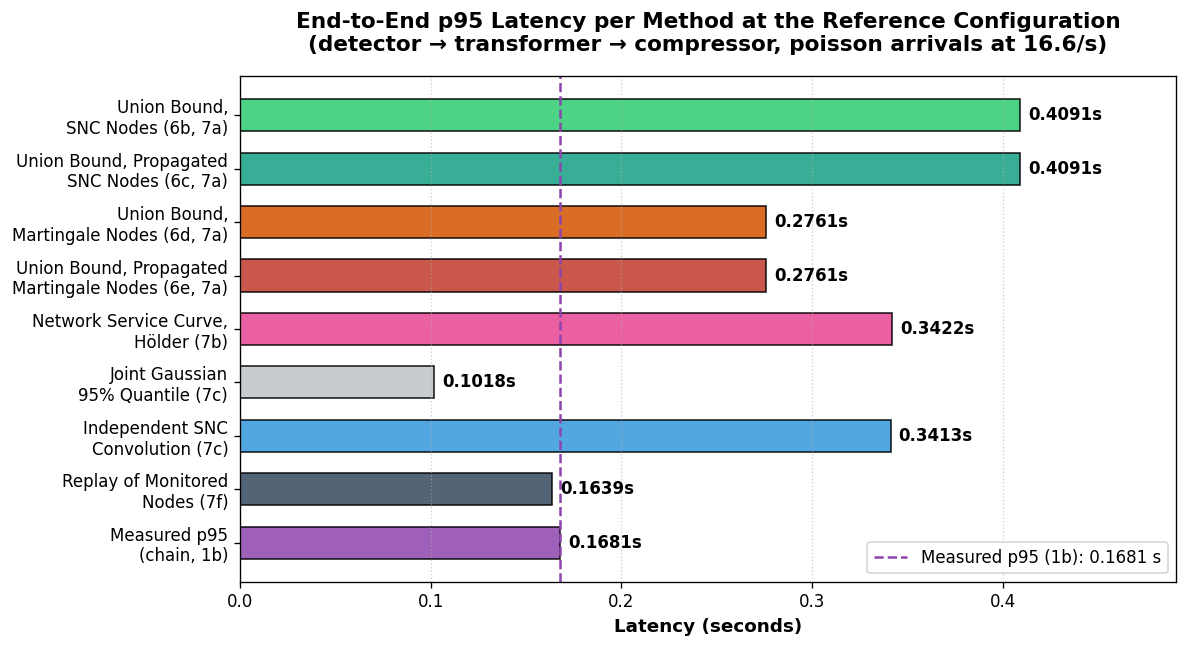

In [23]:
# Bar chart of the reference configuration: ordered by subsection (7a to 7f), ground truth last; gray: execution times
# only (no queue), colored: latency bounds and the replay, purple: ground truth
labels = [
    'Union Bound,\nSNC Nodes (6b, 7a)',
    'Union Bound, Propagated\nSNC Nodes (6c, 7a)',
    'Union Bound,\nMartingale Nodes (6d, 7a)',
    'Union Bound, Propagated\nMartingale Nodes (6e, 7a)',
    'Network Service Curve,\nHölder (7b)',
    f'Joint Gaussian\n{p_str}% Quantile (7c)',
    'Independent SNC\nConvolution (7c)',
    'Replay of Monitored\nNodes (7f)',
    f'Measured p{p_str}\n(chain, 1b)'
]
values = [union_snc_bound, propagated_bound, martingale_bound, propagated_martingale_bound, network_bound, joint_gaussian_bound,
          independent_bound, replay_bound, oracle_queueing_p_latency]
colors = ['#2ecc71', '#16a085', '#d35400', '#c0392b', '#e84393', '#bdc3c7', '#3498db', '#34495e', '#8e44ad']

plt.figure(figsize=(10, 5.5), dpi=120)
bars = plt.barh(labels, values, color=colors, edgecolor='black', alpha=0.85, height=0.6)
plt.axvline(x=oracle_queueing_p_latency, color='#8e44ad', linestyle='--', linewidth=1.5,
            label=f'Measured p{p_str} (1b): {oracle_queueing_p_latency:.4f} s')
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.01 * max(values), bar.get_y() + bar.get_height() / 2, f'{width:.4f}s', va='center', ha='left', fontsize=10, fontweight='bold')
plt.xlim(0, max(values) * 1.2)
plt.xlabel('Latency (seconds)', fontsize=11, fontweight='bold')
plt.title(f"End-to-End p{p_str} Latency per Method at the Reference Configuration\n({' → '.join(service_names)}, "
          f"{reference_workload['process']} arrivals at {reference_rate:.3g}/s)", fontsize=13, fontweight='bold', pad=15)
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

In [24]:
guaranteed = {"union bound, SNC nodes (6b, 7a)": union_snc_bound, "union bound, propagated SNC nodes (6c, 7a)": propagated_bound,
              "union bound, martingale nodes (6d, 7a)": martingale_bound, "union bound, propagated martingale nodes (6e, 7a)": propagated_martingale_bound,
              "network service curve, Hölder (7b)": network_bound}
truth = oracle_queueing_p_latency
shift = oracle_independent_p_latency - node_sum_p_latency
# share of the time every worker of the busiest service of the reference run is busy: arrival rate x its mean measured
# execution time / its workers
reference_utilization = reference_rate * (chain_run_execution_times(experiment, split[1])[reference].mean(axis=0)
                                          / np.concatenate(reference_workers)).max()
display(Markdown(
    f"**What this shows** ({reference_workload['process']} arrivals at {reference_rate:.3g}/s; multiples are of the measured p{p_str} of {truth:.3f} s, 1b).\n"
    "- **Compositions with a guarantee (7a, 7b):** " + ", ".join(f"{name} {value:.3f} s ({ratio(value / truth)})" for name, value in guaranteed.items())
    + f". The tightest here: {min(guaranteed, key=guaranteed.get)}. The network service curve (7b) is "
    f"{'tighter' if network_bound < union_snc_bound else 'looser'} than the union bound over the same SNC node moments (6b, 7a). "
    + ("All of them lie above the measured quantile here." if min(guaranteed.values()) >= truth else
       "Not all of them lie above the measured quantile here: " + ", ".join(name for name, value in guaranteed.items() if value < truth) + ".")
    + "\n"
    f"- **Composition by independence (7c):** the joint Gaussian quantile ({joint_gaussian_bound:.3f} s, "
    f"{ratio(joint_gaussian_bound / truth)}) has no queue and {'falls below' if joint_gaussian_bound < truth else 'lies above'} "
    f"the measured p{p_str}; the independent SNC convolution ({ratio(independent_bound / truth)}) includes the queue but assumes "
    f"independent nodes. Removing the dependence between the measured node latencies moves the p{p_str} of their sum "
    f"{'down' if shift < 0 else 'up'} by {abs(shift) * 1000:.1f} ms; the paired test on the same items finds "
    + ("that assuming independence significantly underestimates the tail here" if independence_upper[0] < 0 else
       "no significant difference at this single configuration")
    + f" (at {pct(coverage_check['confidence'])} confidence).\n"
    f"- **Replay of monitored node latencies (7f, no guarantee):** {replay_bound:.3f} s ({ratio(replay_bound / truth)}), built from "
    f"every service monitored on its own, without a held-out run. It {'falls below' if replay_bound < truth else 'lies above'} the "
    f"measured p{p_str} here; the side depends on how the chain changes the arrivals of its services (7f), not on a bound.\n"
    f"- **One configuration only:** at the reference configuration every worker of the busiest service is busy {pct(reference_utilization)} of "
    "the time (arrival rate × its mean measured execution time ÷ its workers). A single configuration cannot show coverage: a method without a guarantee can be above the ground truth "
    "here and below it elsewhere. Section 6f shows the coverage of the node bounds over all runs of this chain; `2_evaluation.ipynb` "
    "measures the coverage of the compositions over all runs of the chains of the first campaign."))

**What this shows** (poisson arrivals at 16.6/s; multiples are of the measured p95 of 0.168 s, 1b).
- **Compositions with a guarantee (7a, 7b):** union bound, SNC nodes (6b, 7a) 0.409 s (2.43×), union bound, propagated SNC nodes (6c, 7a) 0.409 s (2.43×), union bound, martingale nodes (6d, 7a) 0.276 s (1.64×), union bound, propagated martingale nodes (6e, 7a) 0.276 s (1.64×), network service curve, Hölder (7b) 0.342 s (2.04×). The tightest here: union bound, martingale nodes (6d, 7a). The network service curve (7b) is tighter than the union bound over the same SNC node moments (6b, 7a). All of them lie above the measured quantile here.
- **Composition by independence (7c):** the joint Gaussian quantile (0.102 s, 0.61×) has no queue and falls below the measured p95; the independent SNC convolution (2.03×) includes the queue but assumes independent nodes. Removing the dependence between the measured node latencies moves the p95 of their sum up by 0.9 ms; the paired test on the same items finds no significant difference at this single configuration (at 95% confidence).
- **Replay of monitored node latencies (7f, no guarantee):** 0.164 s (0.98×), built from every service monitored on its own, without a held-out run. It falls below the measured p95 here; the side depends on how the chain changes the arrivals of its services (7f), not on a bound.
- **One configuration only:** at the reference configuration every worker of the busiest service is busy 52% of the time (arrival rate × its mean measured execution time ÷ its workers). A single configuration cannot show coverage: a method without a guarantee can be above the ground truth here and below it elsewhere. Section 6f shows the coverage of the node bounds over all runs of this chain; `2_evaluation.ipynb` measures the coverage of the compositions over all runs of the chains of the first campaign.

## 8. Design Space Sensitivity & Sweep Analysis

Not available for real data. `1_method_synthetic.ipynb` sweeps a grid over CPU and quality and simulates the ground truth at
every grid point. The real services were measured at randomly drawn configurations only, so there is no ground truth
at the points of a grid. In `2_evaluation.ipynb` (B.1, first campaign), the held-out runs of a chain take the place of the sweep.

## 9. Composition vs. Depth (RQ2)

Not part of this notebook. `2_evaluation.ipynb` (B.3) compares the compositions on the chains of the first campaign with
2 to 10 services.